# 03 · Baseline PD model (logistic regression)

The first real model. Deliberately simple, so that later versions (WoE scorecard, gradient boosting) have something to beat.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score

from creditrisk import config
from creditrisk.data import load_processed, make_splits
from creditrisk.evaluation import (
    calibration_table, plot_calibration, plot_roc, sub_grade_to_rank, summary_table,
)
from creditrisk.features import CATEGORICAL_FEATURES, NUMERIC_FEATURES
from creditrisk.models import build_logistic_pipeline, coefficient_table

pd.set_option("display.float_format", "{:,.4f}".format)
config.FIGURES.mkdir(parents=True, exist_ok=True)

## Why logistic regression?

Logistic regression models the **log-odds** of default as a weighted sum of features:

$$\log\frac{PD}{1-PD} = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$$

then squashes that into a probability between 0 and 1.

Banks still use it for most retail scorecards because:

- **Each coefficient has a meaning** you can explain to a regulator, a model validator, or a customer who was declined.
- It's **stable**: small changes in data don't flip the results.
- It produces **probabilities**, not just rankings, which feed straight into expected loss and capital.

## Validation design: three datasets

| Set | Loans | Purpose |
|---|---|---|
| **train** | 80% of 2007-2014, random | fit the model |
| **valid** (in-time) | other 20% of 2007-2014 | check it isn't overfitting |
| **oot** (out-of-time) | all of 2015 | check it works on *future* borrowers |

The out-of-time set is the one that matters most. A bank deploys a model on applicants who arrive *after* it was built, so testing on a later period mimics real use.

In [2]:
df = load_processed()
splits = make_splits(df)
pd.DataFrame({name: {"loans": len(d), "default_rate": d["default"].mean()} for name, d in splits.items()}).T

,loans,default_rate
train,"268,446.0000",0.1306
valid,"67,112.0000",0.1306
oot,"283,026.0000",0.1489


## Class imbalance

Most loans don't default, so the classes are imbalanced. That has two consequences:

- **Accuracy is useless.** A "model" that predicts *nobody* defaults is right for most loans and worthless. We use AUC/Gini instead, which measure ranking.
- **We don't rebalance the data** (no oversampling, no `class_weight="balanced"`). Those tricks can help ranking in some problems, but they shift the predicted probabilities away from real default rates. For a PD model, the probability itself is the product, so we keep the real mix.

In [3]:
pipeline = build_logistic_pipeline(NUMERIC_FEATURES, CATEGORICAL_FEATURES)
features = NUMERIC_FEATURES + CATEGORICAL_FEATURES
pipeline.fit(splits["train"][features], splits["train"]["default"])

results = {
    name: (d["default"], pipeline.predict_proba(d[features])[:, 1])
    for name, d in splits.items()
}
summary = summary_table(results)
summary

,loans,observed_default_rate,mean_predicted_pd,auc,gini,ks,brier
train,"268,446.0000",0.1306,0.1305,0.6588,0.3175,0.2289,0.1095
valid,"67,112.0000",0.1306,0.1310,0.6607,0.3214,0.2339,0.1093
oot,"283,026.0000",0.1489,0.1335,0.6609,0.3217,0.2335,0.1219


## Reading the metrics

- **AUC:** pick a random defaulter and a random non-defaulter. AUC is the chance the model gives the defaulter the higher PD. 0.5 = coin flip, 1.0 = perfect.
- **Gini = 2 × AUC − 1.** Same information, rescaled to 0-1. UK banks report Gini. Application scorecards for unsecured lending commonly land somewhere around 0.4-0.6, but it depends heavily on the product and data.
- **KS:** the biggest gap between the cumulative PD distributions of defaulters and non-defaulters. Another ranking measure; popular in scorecard teams.
- **Brier score:** mean squared error of the probabilities. Lower is better; it rewards both ranking *and* getting the level right.
- **Mean predicted PD vs observed default rate:** the simplest calibration check.

**What to compare:**

- train vs valid: a big drop means overfitting. With a simple model and lots of data, they should be close.
- valid vs oot: a drop here is **population drift**: 2015 borrowers differ from 2007-2014 ones.

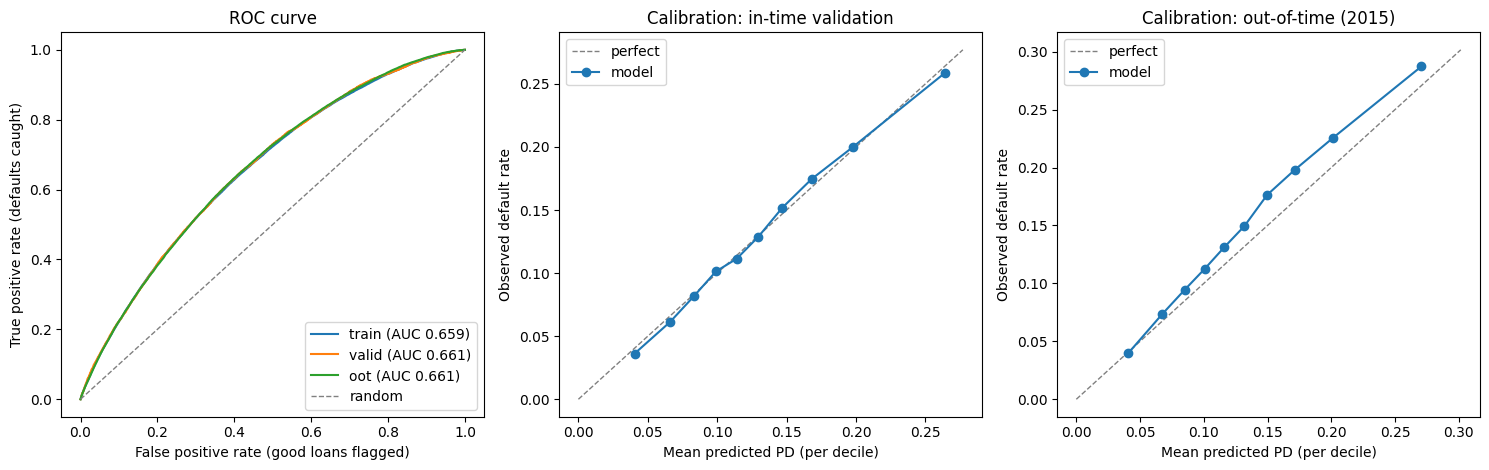

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
plot_roc(results, ax=axes[0])
plot_calibration(calibration_table(*results["valid"]), title="Calibration: in-time validation", ax=axes[1])
plot_calibration(calibration_table(*results["oot"]), title="Calibration: out-of-time (2015)", ax=axes[2])
fig.tight_layout()
fig.savefig(config.FIGURES / "03_roc_and_calibration.png", dpi=150)

In [5]:
calibration_table(*results["oot"])

,loans,mean_predicted_pd,observed_default_rate,ratio_obs_to_pred
bin,,,,
1,28303,0.0408,0.0398,0.9762
2,28303,0.0673,0.0733,1.0902
3,28302,0.0851,0.0946,1.1114
4,28303,0.1008,0.1127,1.1177
5,28302,0.1160,0.1311,1.1304
6,28303,0.1319,0.1496,1.1336
7,28302,0.1497,0.1764,1.1782
8,28303,0.1714,0.1981,1.1554
9,28302,0.2016,0.2258,1.1202


## Reading calibration

Each point is a tenth of the loans, sorted by predicted PD. On the dashed line, predicted PD equals the actual default rate.

- Points **above** the line: the model **under-predicts** risk for that group (more defaults than it expected).
- Points **below**: it **over-predicts**.

If the in-time chart sits on the line but the out-of-time one is shifted, the *ranking* still works but the *level* has moved because 2015's default rate differs from the training years. Banks deal with this by **recalibrating** the intercept periodically and by monitoring population stability (PSI), which we'll add in v2.

## What drives the model

Features were standardised, so each numeric coefficient is the change in log-odds for a **one standard deviation** increase. The odds ratio is `exp(coefficient)`: e.g. 0.70 means the odds of default fall by 30% per standard deviation.

In [6]:
coefs = coefficient_table(pipeline)
coefs.head(15)

,feature,coefficient,odds_ratio
0,cat__purpose_small_business,0.4942,1.6391
1,cat__purpose_credit_card,-0.4891,0.6132
2,cat__home_ownership_MORTGAGE,-0.4271,0.6524
3,cat__verification_status_Not Verified,-0.3881,0.6783
4,cat__home_ownership_OWN,-0.3725,0.6890
5,num__fico,-0.3551,0.7011
6,cat__verification_status_Verified,-0.3520,0.7033
7,cat__purpose_car,-0.3348,0.7155
8,cat__verification_status_Source Verified,-0.2939,0.7454
9,cat__purpose_debt_consolidation,-0.2792,0.7564


**Sense-check the signs**, as a model validator would:

- FICO: negative (higher score → fewer defaults)
- debt-to-income, loan-to-income, recent credit enquiries: positive
- income: negative

If a sign looks wrong, the usual causes are **correlated features** sharing the effect (e.g. `open_acc` and `total_acc`) or **selection effects** like verification status. Note it rather than hide it: that's what the limitations section is for.

## Benchmark: how close do we get to Lending Club's own grade?

`sub_grade` (A1 best → G5 worst) is the output of Lending Club's credit model, which used more data than we have. Turning it into a rank and computing its AUC gives a **champion** to compare against.

In [7]:
oot = splits["oot"]
benchmark = pd.DataFrame({
    "out_of_time_auc": [
        roc_auc_score(oot["default"], results["oot"][1]),
        roc_auc_score(oot["default"], sub_grade_to_rank(oot["sub_grade"])),
    ]
}, index=["our baseline (application data only)", "Lending Club sub_grade"])
benchmark["gini"] = 2 * benchmark["out_of_time_auc"] - 1
benchmark

,out_of_time_auc,gini
our baseline (application data only),0.6609,0.3217
Lending Club sub_grade,0.6787,0.3573


Lending Club's grade will usually win: it's built on richer bureau data and their underwriting experience. The interesting number is **how big the gap is**, because it tells you how much of their grade you've reproduced from public application fields alone.

> **Interview angle:** "I excluded Lending Club's grade from my features because it's the output of their model, then used it as a champion benchmark. My challenger got to X Gini against their Y."

In [8]:
results_dir = config.PROJECT_ROOT / "reports"
summary.to_csv(results_dir / "v1_performance.csv")
benchmark.to_csv(results_dir / "v1_benchmark.csv")
coefs.to_csv(results_dir / "v1_coefficients.csv", index=False)
print("Saved results to reports/")

Saved results to reports/


## Where v1 leaves us

- A working, leakage-free PD model with an honest validation design.
- Known weaknesses for v2 to fix: straight-line effects (fix: WoE binning), no stability monitoring (fix: PSI), and calibration drift on 2015 (fix: recalibration).